<a href="https://colab.research.google.com/github/night-marionette/Pneumonia-Triage/blob/main/01_model.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [5]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [6]:
import os
OUT_DIR = '/content/drive/MyDrive/PneumoniaTriage'
os.makedirs(OUT_DIR, exist_ok=True)
print("Folder ready:", OUT_DIR)

Folder ready: /content/drive/MyDrive/PneumoniaTriage


In [7]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("paultimothymooney/chest-xray-pneumonia")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'chest-xray-pneumonia' dataset.
Path to dataset files: /kaggle/input/chest-xray-pneumonia


In [8]:
import os
import random
import re
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms, models
from collections import defaultdict

# 1. FIX SEEDS FOR REPRODUCIBILITY
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
set_seed(42)

# 2. SETUP PATHS & DEVICE
DATA_DIR = '/kaggle/input/chest-xray-pneumonia/chest_xray'
OUT_DIR = '/content/drive/MyDrive/PneumoniaTriage'
os.makedirs(OUT_DIR, exist_ok=True)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

# 3. TRANSFORMS
# train_tf has augmentation (flip); eval_tf has NO augmentation
train_tf = transforms.Compose([
    transforms.Grayscale(num_output_channels=3),
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
])

eval_tf = transforms.Compose([
    transforms.Grayscale(num_output_channels=3),
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
])

# 4. LOAD DATA WITH PATIENT-LEVEL SPLIT (FIXES ISSUE A: NO DATA LEAKAGE)
train_folder = datasets.ImageFolder(f'{DATA_DIR}/train', transform=train_tf)
val_folder   = datasets.ImageFolder(f'{DATA_DIR}/train', transform=eval_tf)
test_ds      = datasets.ImageFolder(f'{DATA_DIR}/test', transform=eval_tf)

def extract_patient_id(path):
    fname = os.path.basename(path)
    # Match patient prefixes like "person100_bacteria_475.jpeg" or "IM-0115-0001.jpeg"
    match = re.match(r'^(person\d+|IM-\d+|NORMAL2-IM-\d+)', fname)
    return match.group(1) if match else fname

# Group training sample indices by patient ID
patient_to_indices = defaultdict(list)
for idx, (path, _) in enumerate(train_folder.samples):
    pid = extract_patient_id(path)
    patient_to_indices[pid].append(idx)

# Split patient IDs 85% train / 15% validation
all_patients = sorted(list(patient_to_indices.keys()))
rng = random.Random(42)
rng.shuffle(all_patients)

val_patient_count = int(0.15 * len(all_patients))
val_patients = set(all_patients[:val_patient_count])
train_patients = set(all_patients[val_patient_count:])

train_indices = [idx for pid in train_patients for idx in patient_to_indices[pid]]
val_indices   = [idx for pid in val_patients   for idx in patient_to_indices[pid]]

train_ds = Subset(train_folder, train_indices)
val_ds   = Subset(val_folder, val_indices)

train_loader = DataLoader(train_ds, batch_size=32, shuffle=True, num_workers=2)
val_loader   = DataLoader(val_ds, batch_size=32, shuffle=False, num_workers=2)
test_loader  = DataLoader(test_ds, batch_size=32, shuffle=False, num_workers=2)

print(f"Classes: {train_folder.classes}")
print(f"Unique Patients: {len(all_patients)} (Train: {len(train_patients)}, Val: {len(val_patients)})")
print(f"Images -> Train: {len(train_ds)} | Val: {len(val_ds)} | Test: {len(test_ds)}")

# 5. MODEL (PRETRAINED RESNET-18)
model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
model.fc = nn.Linear(model.fc.in_features, 2)
model = model.to(device)

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=1e-4)

# 6. TRAIN LOOP
print("\nStarting training (approx. 5 minutes on T4)...")
for epoch in range(3):
    model.train()
    running_loss = 0.0
    for imgs, labels in train_loader:
        imgs, labels = imgs.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(imgs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        running_loss += loss.item()

    # Validation
    model.eval()
    correct, total = 0, 0
    with torch.no_grad():
        for imgs, labels in val_loader:
            imgs, labels = imgs.to(device), labels.to(device)
            outputs = model(imgs)
            _, predicted = torch.max(outputs, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    print(f"Epoch {epoch+1}/3 | Train Loss: {running_loss/len(train_loader):.3f} | Val Acc: {100 * correct / total:.1f}%")

# 7. SAVE MODEL WEIGHTS
model_save_path = f'{OUT_DIR}/resnet18_pneumonia.pth'
torch.save(model.state_dict(), model_save_path)
print(f"Saved trained model weights to: {model_save_path}")

# 8. GENERATE FINAL TEST_SCORES.CSV
print("\nGenerating final test scores...")
model.eval()
all_scores = []
all_labels = []

with torch.no_grad():
    for imgs, labels in test_loader:
        imgs = imgs.to(device)
        outputs = model(imgs)
        probs = torch.softmax(outputs, dim=1)[:, 1] # Probability of Pneumonia
        all_scores.extend(probs.cpu().numpy())
        all_labels.extend(labels.numpy())

df = pd.DataFrame({
    "id": range(len(all_labels)),
    "true_label": all_labels,
    "score": all_scores
})

save_path = f'{OUT_DIR}/test_scores.csv'
df.to_csv(save_path, index=False)
print(f"SUCCESS! Saved {len(df)} rows to {save_path}")

Using device: cuda
Classes: ['NORMAL', 'PNEUMONIA']
Unique Patients: 2846 (Train: 2420, Val: 426)
Images -> Train: 4395 | Val: 821 | Test: 624

Starting training (approx. 5 minutes on T4)...
Epoch 1/3 | Train Loss: 0.102 | Val Acc: 98.5%
Epoch 2/3 | Train Loss: 0.030 | Val Acc: 98.7%
Epoch 3/3 | Train Loss: 0.026 | Val Acc: 97.4%
Saved trained model weights to: /content/drive/MyDrive/PneumoniaTriage/resnet18_pneumonia.pth

Generating final test scores...
SUCCESS! Saved 624 rows to /content/drive/MyDrive/PneumoniaTriage/test_scores.csv


=== BASELINE (Always guess Pneumonia) ===
Accuracy: 62.5%

=== RESNET-18 MODEL EVALUATION (@ 0.5 Threshold) ===
Accuracy: 89.4%
Pneumonia Recall (Sick Kids Caught): 99.0% | Missed (FN): 4
False Alarms (Healthy Kids Flagged): 62 | Specificity: 73.5%



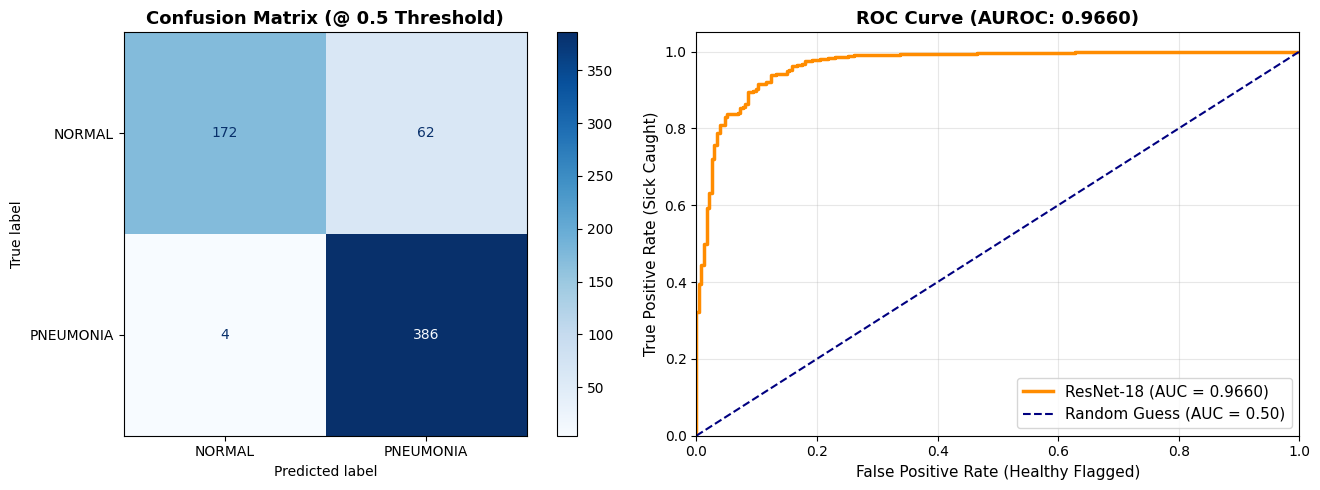


Showing 3 missed pneumonia cases...


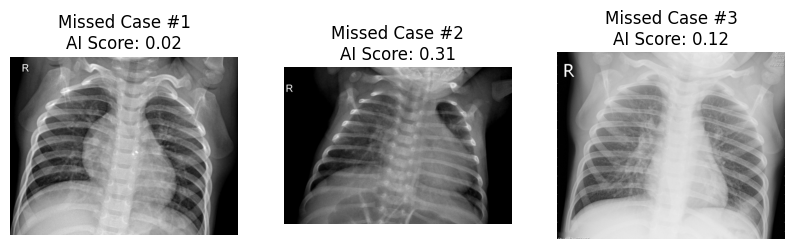

In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, roc_curve, auc

labels_array = np.array(all_labels)
scores_array = np.array(all_scores)
preds = (scores_array >= 0.5).astype(int)

# 1. TEXT METRICS
print("=== BASELINE (Always guess Pneumonia) ===")
base_preds = np.ones_like(labels_array)
print(f"Accuracy: {(base_preds == labels_array).mean()*100:.1f}%\n")

print("=== RESNET-18 MODEL EVALUATION (@ 0.5 Threshold) ===")
print(f"Accuracy: {(preds == labels_array).mean()*100:.1f}%")

tp = ((preds == 1) & (labels_array == 1)).sum()
fn = ((preds == 0) & (labels_array == 1)).sum()
fp = ((preds == 1) & (labels_array == 0)).sum()
tn = ((preds == 0) & (labels_array == 0)).sum()

print(f"Pneumonia Recall (Sick Kids Caught): {tp / (tp + fn) * 100:.1f}% | Missed (FN): {fn}")
print(f"False Alarms (Healthy Kids Flagged): {fp} | Specificity: {tn / (tn + fp) * 100:.1f}%\n")

# 2. REPORT CARD CHARTS: CONFUSION MATRIX & ROC-AUC (FIXES ISSUE B)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Chart 1: Confusion Matrix
cm = confusion_matrix(labels_array, preds)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['NORMAL', 'PNEUMONIA'])
disp.plot(cmap='Blues', ax=axes[0], values_format='d')
axes[0].set_title('Confusion Matrix (@ 0.5 Threshold)', fontsize=13, fontweight='bold')

# Chart 2: ROC-AUC Curve
fpr, tpr, _ = roc_curve(labels_array, scores_array)
roc_auc = auc(fpr, tpr)
axes[1].plot(fpr, tpr, color='darkorange', lw=2.5, label=f'ResNet-18 (AUC = {roc_auc:.4f})')
axes[1].plot([0, 1], [0, 1], color='navy', lw=1.5, linestyle='--', label='Random Guess (AUC = 0.50)')
axes[1].set_xlim([0.0, 1.0])
axes[1].set_ylim([0.0, 1.05])
axes[1].set_xlabel('False Positive Rate (Healthy Flagged)', fontsize=11)
axes[1].set_ylabel('True Positive Rate (Sick Caught)', fontsize=11)
axes[1].set_title(f'ROC Curve (AUROC: {roc_auc:.4f})', fontsize=13, fontweight='bold')
axes[1].legend(loc="lower right", fontsize=11)
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig('/content/model_report_card.png', dpi=200)
plt.show()

# 3. DISPLAY MISSED PNEUMONIA CASES
miss_idx = np.where((labels_array == 1) & (preds == 0))[0]
print(f"\nShowing {min(3, len(miss_idx))} missed pneumonia cases...")
if len(miss_idx) > 0:
    fig, axes = plt.subplots(1, min(3, len(miss_idx)), figsize=(10, 3))
    if len(miss_idx) == 1:
        axes = [axes]
    for i, ax in enumerate(axes):
        idx = miss_idx[i]
        img_path = test_ds.samples[idx][0]
        score = scores_array[idx]
        ax.imshow(Image.open(img_path).convert("L"), cmap="gray")
        ax.set_title(f"Missed Case #{i+1}\nAI Score: {score:.2f}")
        ax.axis("off")
    plt.show()

In [10]:
!pip install grad-cam -q
import cv2
import numpy as np
import matplotlib.pyplot as plt
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
from PIL import Image

# 1. Tell Grad-CAM to look at the last layer of our ResNet model
target_layers = [model.layer4[-1]]
cam = GradCAM(model=model, target_layers=target_layers)

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


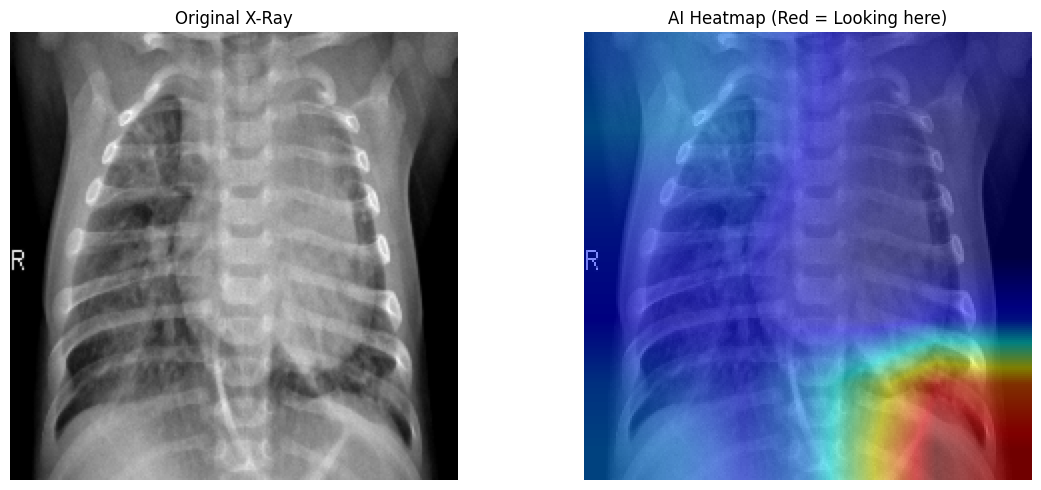

In [11]:
# 1. Find an image in the test set that ACTUALLY has pneumonia
labels_array = np.array(all_labels)
pneumonia_idx = np.where(labels_array == 1)[0][0] # Grabs the first sick patient
img_path = test_ds.samples[pneumonia_idx][0]

# 2. Prepare the image for the model
raw_img = cv2.imread(img_path)
raw_img = cv2.cvtColor(raw_img, cv2.COLOR_BGR2RGB)
rgb_img = cv2.resize(raw_img, (224, 224))
rgb_img_float = np.float32(rgb_img) / 255

input_tensor = eval_tf(Image.open(img_path).convert("RGB")).unsqueeze(0).to(device)

# 3. Generate the heatmap for the "PNEUMONIA" class (index 1)
targets = [ClassifierOutputTarget(1)]
grayscale_cam = cam(input_tensor=input_tensor, targets=targets)[0, :]
visualization = show_cam_on_image(rgb_img_float, grayscale_cam, use_rgb=True)

# 4. Plot them side-by-side
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].imshow(rgb_img)
axes[0].set_title("Original X-Ray")
axes[0].axis("off")

axes[1].imshow(visualization)
axes[1].set_title("AI Heatmap (Red = Looking here)")
axes[1].axis("off")

plt.tight_layout()
plt.show()

In [12]:
!pip install gradio -q
import gradio as gr
from PIL import Image
import torch
import cv2
import numpy as np
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget

model.eval()
target_layers = [model.layer4[-1]]
cam = GradCAM(model=model, target_layers=target_layers)

def predict_and_explain(image, threshold):
    if image is None:
        return None, None

    # 1. Preprocess for Model & Grad-CAM
    pil_img = image.convert('L').convert('RGB')
    resized_rgb = pil_img.resize((224, 224))
    rgb_float = np.float32(resized_rgb) / 255.0

    input_tensor = eval_tf(pil_img).unsqueeze(0).to(device)

    # 2. Model Prediction
    with torch.no_grad():
        outputs = model(input_tensor)
        probs = torch.softmax(outputs, dim=1)[0]

    normal_prob = float(probs[0].item())
    pneumonia_prob = float(probs[1].item())

    # 3. Triage Decision based on Slider Threshold
    triage_decision = "PNEUMONIA (PRIORITY TRIAGE)" if pneumonia_prob >= threshold else "NORMAL (STANDARD QUEUE)"
    label_output = {
        f"TRIAGE RESULT: {triage_decision}": 1.0,
        "Pneumonia Probability": pneumonia_prob,
        "Normal Probability": normal_prob
    }

    # 4. Generate Grad-CAM Heatmap
    grayscale_cam = cam(input_tensor=input_tensor, targets=[ClassifierOutputTarget(1)])[0, :]
    heatmap_overlay = show_cam_on_image(rgb_float, grayscale_cam, use_rgb=True)

    return label_output, heatmap_overlay

demo = gr.Interface(
    fn=predict_and_explain,
    inputs=[
        gr.Image(type="pil", label="Upload Pediatric Chest X-Ray"),
        gr.Slider(minimum=0.1, maximum=0.99, value=0.5, step=0.05, label="Triage Threshold Cutoff")
    ],
    outputs=[
        gr.Label(label="AI Diagnosis & Confidence"),
        gr.Image(type="numpy", label="Grad-CAM Lung Heatmap (Red = AI Focus)")
    ],
    title="Pediatric Pneumonia AI Triage & Explainability",
    description="Upload a chest X-ray and adjust the triage slider. The model outputs the priority decision and a Grad-CAM heatmap highlighting suspicious lung areas."
)

demo.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://294fe12ca95c3510a9.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [13]:
import pandas as pd
import numpy as np

df = pd.read_csv('/content/drive/MyDrive/PneumoniaTriage/test_scores.csv')
labels_array = df['true_label'].values
scores_array = df['score'].values
print(f"Loaded {len(df)} rows | pneumonia: {(labels_array==1).sum()} | normal: {(labels_array==0).sum()}")

Loaded 624 rows | pneumonia: 390 | normal: 234


In [14]:
print(f"{'Thresh':>7} | {'Acc':>6} | {'Recall':>7} | {'FN':>3} | {'FP':>4} | {'Spec':>6}")
print("-" * 55)

for t in [0.5, 0.6, 0.7, 0.75, 0.8, 0.85, 0.9, 0.95]:
    p = (scores_array >= t).astype(int)
    tp = ((p==1)&(labels_array==1)).sum(); fn = ((p==0)&(labels_array==1)).sum()
    fp = ((p==1)&(labels_array==0)).sum(); tn = ((p==0)&(labels_array==0)).sum()
    acc  = (p==labels_array).mean()*100
    rec  = tp/(tp+fn)*100
    spec = tn/(tn+fp)*100
    print(f"{t:>7.2f} | {acc:>5.1f}% | {rec:>6.1f}% | {fn:>3} | {fp:>4} | {spec:>5.1f}%")

 Thresh |    Acc |  Recall |  FN |   FP |   Spec
-------------------------------------------------------
   0.50 |  89.4% |   99.0% |   4 |   62 |  73.5%
   0.60 |  90.4% |   98.5% |   6 |   54 |  76.9%
   0.70 |  91.0% |   97.9% |   8 |   48 |  79.5%
   0.75 |  91.2% |   97.4% |  10 |   45 |  80.8%
   0.80 |  91.5% |   97.2% |  11 |   42 |  82.1%
   0.85 |  91.5% |   96.4% |  14 |   39 |  83.3%
   0.90 |  91.0% |   95.1% |  19 |   37 |  84.2%
   0.95 |  90.9% |   92.8% |  28 |   29 |  87.6%


In [15]:
import hashlib
h = hashlib.md5(open('/content/drive/MyDrive/PneumoniaTriage/test_scores.csv', 'rb').read()).hexdigest()
print('Hash of YOUR file:', h)

Hash of YOUR file: 8847f5df00b3c338a69bf824eeb8e228
